# CS376 Programming HW 1

이번 homework에서는 scatch로 신경망을 구현하는 코드를 작성하고, 간단한 데이터베이스를 직접 생성하여 만든 신경망이 잘 작동하는지 확인하고 여러 데이터를 조정하여 진행한다.

### Import Modules

In [1]:
import numpy as np

### Generate Datas

In [2]:
DB_NUM = 100000

x_data = []
y_data = []
for i in range(DB_NUM):
    x1 = np.random.random()
    x2 = np.random.random()
    y = x1 * x2
    x_data.append([x1, x2])
    y_data.append([y])

print("Sample Data:")
print("X:", x_data[:5])
print("Y:", y_data[:5])

Sample Data:
X: [[0.5432996206819746, 0.0595573069884926], [0.21013621458385534, 0.11725536389049962], [0.933910825390561, 0.7134390222689061], [0.6390142626834076, 0.8850683621966302], [0.18656236955354333, 0.06254932298428673]]
Y: [[0.03235746229568794], [0.02463959830760207], [0.6662884261529889], [0.5655713068934908], [0.011669349909918442]]


### Implement Neural Network

In [3]:
class NeuralNetwork:
    def __init__(self, input_size, hidden_layers, output_size, activation_type='relu', last_layer_activation=None):
        self.input_size = input_size
        self.hidden_layers = hidden_layers
        self.output_size = output_size
        self.activation_type = activation_type
        self.last_layer_activation = last_layer_activation

        self._initialize_variables()
        
    def _initialize_variables(self):
        """Initialize weights and biases for the neural network using He initialization."""

        layer_sizes = [self.input_size] + self.hidden_layers + [self.output_size]
        self.variables = []
        for i in range(len(layer_sizes) - 1):
            # He initialization
            weight_matrix = np.random.normal(0, np.sqrt(2 / layer_sizes[i]), (layer_sizes[i], layer_sizes[i + 1]))
            # initialize biases to zero
            bias_vector = np.full((1, layer_sizes[i + 1]), 0.01)
            self.variables.append((weight_matrix, bias_vector))

    def _relu(self, x):
        """ReLU activation function."""
        return np.maximum(0, x)
    
    def _relu_derivative(self, x):
        """Derivative of ReLU activation function."""
        return (x > 0).astype(float)
    
    def _sigmoid(self, x):
        """Sigmoid activation function."""
        return 1 / (1 + np.exp(-x))
    
    def _sigmoid_derivative(self, x):
        """Derivative of Sigmoid activation function."""
        sig = self._sigmoid(x)
        return sig * (1 - sig)
    
    def activation(self, X, activation_type: str | None = 'relu'):
        """Apply activation function."""

        match(activation_type):
            case 'relu':
                return self._relu(X)
            case 'sigmoid':
                return self._sigmoid(X)
            case None:
                return X
            case _:
                raise ValueError("Unsupported activation type. Use 'relu', 'sigmoid', or None.")
            
    def activation_derivative(self, X, activation_type: str | None = 'relu'):
        """Apply derivative of activation function."""

        match(activation_type):
            case 'relu':
                return self._relu_derivative(X)
            case 'sigmoid':
                return self._sigmoid_derivative(X)
            case None:
                return np.ones_like(X)
            case _:
                raise ValueError("Unsupported activation type. Use 'relu', 'sigmoid', or None.")

    def predict(self, X: np.ndarray):
        """Predict output for given input data."""

        A = X.copy()
        for i, (weights, biases) in enumerate(self.variables):
            A = np.dot(A, weights) + biases

            if i != len(self.variables) - 1:
                A = self.activation(A, activation_type=self.activation_type)
            else:
                A = self.activation(A, activation_type=self.last_layer_activation)

        return A
    
    def _feed_forward(self, X: np.ndarray):
        """Perform a feedforward pass through the network."""
        A = X.copy()
        self.Z_values = [None]
        self.A_values = [X]
        for i, (weights, biases) in enumerate(self.variables):
            A = np.dot(A, weights) + biases
            self.Z_values.append(A)
            
            if i != len(self.variables) - 1:
                A = self.activation(A, activation_type=self.activation_type)
            else:
                A = self.activation(A, activation_type=self.last_layer_activation)
            
            self.A_values.append(A)
        
        return A
    
    def back_propagate(self, output, result, learning_rate=0.01):
        """Perform backpropagation and update weights and biases."""
        batch_size = result.shape[0]
        error = output - result # Assuming mean squared error loss derivative

        for i, (weights, biases) in reversed(list(enumerate(self.variables))):
            activation_type = self.last_layer_activation if i == len(self.variables) - 1 else self.activation_type
            deriv = self.activation_derivative(self.Z_values[i + 1], activation_type=activation_type)
            A_prev = self.A_values[i]

            W_delta = np.dot(A_prev.T, error * deriv) / batch_size # average over batch
            b_delta = np.sum(error * deriv, axis=0, keepdims=True) / batch_size # average over batch

            error = np.dot(error * deriv, weights.T)
            
            weights -= learning_rate * W_delta
            biases -= learning_rate * b_delta


    def train(self, X: np.ndarray, y: np.ndarray, epochs=1000, learning_rate=0.01, epoch_log_interval=1000):
        """Train the neural network."""
        epoch_log = []
        for epoch in range(epochs):
            if epoch % epoch_log_interval == 0:
                print(f"Epoch {epoch}")
                predictions = self.predict(X)
                loss = np.sqrt(np.mean((predictions - y) ** 2))
                print(f"Loss (RMSE): {loss}")
                epoch_log.append({
                    'epoch': epoch,
                    'predictions': predictions,
                    'rmse': loss
                })

            output = self._feed_forward(X)
            self.back_propagate(output, y, learning_rate)
        
        return epoch_log

In [4]:
train_test_split_ratio = 0.8
split_index = int(DB_NUM * train_test_split_ratio)
x_train = np.array(x_data)[:split_index]
y_train = np.array(y_data)[:split_index]

x_test = np.array(x_data)[split_index:]
y_test = np.array(y_data)[split_index:]

어차피 렌덤으로 생성된 값들이니 굳이 인덱스 까지 렌덤으로 가져갈 필요는 없다 생각했다.

In [5]:
print("Train X Size:", x_train.shape, "sample:", x_train[:5])
print("Test X Size:", x_test.shape, "sample:", x_test[:5])

print("Train Y Size:", y_train.shape, "sample:", y_train[:5])
print("Test Y Size:", y_test.shape, "sample:", y_test[:5])

Train X Size: (80000, 2) sample: [[0.54329962 0.05955731]
 [0.21013621 0.11725536]
 [0.93391083 0.71343902]
 [0.63901426 0.88506836]
 [0.18656237 0.06254932]]
Test X Size: (20000, 2) sample: [[0.94844523 0.66288051]
 [0.36090858 0.78962991]
 [0.66548072 0.06329437]
 [0.04418183 0.60141752]
 [0.83085355 0.75328407]]
Train Y Size: (80000, 1) sample: [[0.03235746]
 [0.0246396 ]
 [0.66628843]
 [0.56557131]
 [0.01166935]]
Test Y Size: (20000, 1) sample: [[0.62870585]
 [0.28498421]
 [0.04212118]
 [0.02657173]
 [0.62586874]]


In [6]:
nn = NeuralNetwork(input_size=2, hidden_layers=[16, 16], output_size=1, activation_type='relu', last_layer_activation=None)
nn.train(x_train, y_train, epochs=20000, learning_rate=0.001)

predictions = nn.predict(x_test)
test_rmse = np.sqrt(np.mean((predictions - y_test) ** 2))

print("Test RMSE:", test_rmse)

Epoch 0
Loss (RMSE): 0.5211878443744785
Epoch 1000
Loss (RMSE): 0.1713791692229124
Epoch 2000
Loss (RMSE): 0.13168420427073743
Epoch 3000
Loss (RMSE): 0.10669651139394636
Epoch 4000
Loss (RMSE): 0.0908113167516188
Epoch 5000
Loss (RMSE): 0.08047030475333317
Epoch 6000
Loss (RMSE): 0.07340444337307248
Epoch 7000
Loss (RMSE): 0.06833264360847738
Epoch 8000
Loss (RMSE): 0.06455440477613317
Epoch 9000
Loss (RMSE): 0.06164808345820806
Epoch 10000
Loss (RMSE): 0.059340682192184316
Epoch 11000
Loss (RMSE): 0.057468497660156936
Epoch 12000
Loss (RMSE): 0.055920553783469065
Epoch 13000
Loss (RMSE): 0.054622590423399425
Epoch 14000
Loss (RMSE): 0.05352109187073816
Epoch 15000
Loss (RMSE): 0.05257414909065421
Epoch 16000
Loss (RMSE): 0.05174725970326548
Epoch 17000
Loss (RMSE): 0.051020366797984905
Epoch 18000
Loss (RMSE): 0.05037244594461245
Epoch 19000
Loss (RMSE): 0.04978816762244885
Test RMSE: 0.049240323662032494


ReLU를 통하여 학습을 하니 20000회의 epoch을 수행하는데 26분 32초가 소요되었고, 학습하는 동안 꾸준히 Loss값 (RMSE) 가 줄어들으면서 학습이 진행되고 있는 것을 확인 할 수 있었고, test셋에서도, baseline인 0.25 (렌덤 선택 하였을때의 평균값인 0.5의 제곱) 보다 낮은 값이, 오히려 이번 실험에서는 Test set이 더 나은 결과가 나오는 것을 확인 할 수 있었다.

In [7]:
nn = NeuralNetwork(input_size=2, hidden_layers=[16, 16], output_size=1, activation_type='relu', last_layer_activation='relu')
nn.train(x_train, y_train, epochs=1000, learning_rate=0.001)

predictions = nn.predict(x_test)
test_rmse = np.sqrt(np.mean((predictions - y_test) ** 2))

print("Test RMSE:", test_rmse)

Epoch 0
Loss (RMSE): 0.3331206255931388
Test RMSE: 0.33500981815233905


이때 만약 last layer의 activation함수를 relu로 뒀을 경우에는 1/2의 확률로 음수값이 나오면 그냥 0으로 만들어 버리는 특성 때문에 Dying ReLU효과가 일어나서 높은 확률로 0.111774 언저리에서 Loss 값이 고정되는 현상을 관찰 할 수 있었다.

In [8]:
nn = NeuralNetwork(input_size=2, hidden_layers=[16, 16], output_size=1, activation_type='sigmoid', last_layer_activation=None)
nn.train(x_train, y_train, epochs=20000, learning_rate=0.001, epoch_log_interval=100)

predictions = nn.predict(x_test)
test_rmse = np.sqrt(np.mean((predictions - y_test) ** 2))

print("Test RMSE:", test_rmse)

Epoch 0
Loss (RMSE): 0.234729598034126
Epoch 100
Loss (RMSE): 0.2092040818591835
Epoch 200
Loss (RMSE): 0.20153339220896513
Epoch 300
Loss (RMSE): 0.1992852027591824
Epoch 400
Loss (RMSE): 0.19857684625585348
Epoch 500
Loss (RMSE): 0.19829658126781657
Epoch 600
Loss (RMSE): 0.19813462268823195
Epoch 700
Loss (RMSE): 0.19800531236469956
Epoch 800
Loss (RMSE): 0.19788501532592565
Epoch 900
Loss (RMSE): 0.19776721409676665
Epoch 1000
Loss (RMSE): 0.19765011179214728
Epoch 1100
Loss (RMSE): 0.19753321300351548
Epoch 1200
Loss (RMSE): 0.1974163810778661
Epoch 1300
Loss (RMSE): 0.19729957823197547
Epoch 1400
Loss (RMSE): 0.19718279392078514
Epoch 1500
Loss (RMSE): 0.19706602509915003
Epoch 1600
Loss (RMSE): 0.19694927078545074
Epoch 1700
Loss (RMSE): 0.19683253056553143
Epoch 1800
Loss (RMSE): 0.19671580418162626
Epoch 1900
Loss (RMSE): 0.1965990914197345
Epoch 2000
Loss (RMSE): 0.19648239207893411
Epoch 2100
Loss (RMSE): 0.19636570596310865
Epoch 2200
Loss (RMSE): 0.19624903287876366
Epoch 

시그모이드 함수를 activation 함수로 만들었을때, 20k epoch을 돌리는데 26분 정도가 나왔던 ReLU에 비해 두배에 가까운 43분 21초 가 걸리면서 학습에 걸리는 시간이 늘어나는 것을 확인 할 수 있었다. 이에 반해 정확도 증가는 오히려 ReLU보다 더 낮게 나와서 특별한 상황이 아니면 모든 activation함수를 sigmoid로 하기에는 메리트가 없다고 생각된다.

### Check RMSE over training epochs

In [9]:
nn = NeuralNetwork(input_size=2, hidden_layers=[16, 16], output_size=1, activation_type='relu', last_layer_activation=None)
epoch_log = nn.train(x_train, y_train, epochs=20100, learning_rate=0.001, epoch_log_interval=100)

predictions = nn.predict(x_test)
test_rmse = np.sqrt(np.mean((predictions - y_test) ** 2))

Epoch 0
Loss (RMSE): 1.170796413889423
Epoch 100
Loss (RMSE): 0.3433438051542778
Epoch 200
Loss (RMSE): 0.2220631843900463
Epoch 300
Loss (RMSE): 0.1868950887246658
Epoch 400
Loss (RMSE): 0.17149007234699362
Epoch 500
Loss (RMSE): 0.1617686352688175
Epoch 600
Loss (RMSE): 0.15554827323436007
Epoch 700
Loss (RMSE): 0.15104155457520813
Epoch 800
Loss (RMSE): 0.1471522282078041
Epoch 900
Loss (RMSE): 0.14356783461998662
Epoch 1000
Loss (RMSE): 0.14017179518071388
Epoch 1100
Loss (RMSE): 0.13691548760359346
Epoch 1200
Loss (RMSE): 0.13376926000111256
Epoch 1300
Loss (RMSE): 0.130715660568148
Epoch 1400
Loss (RMSE): 0.127743412104246
Epoch 1500
Loss (RMSE): 0.12483927930300208
Epoch 1600
Loss (RMSE): 0.12199352036782395
Epoch 1700
Loss (RMSE): 0.11920099427989374
Epoch 1800
Loss (RMSE): 0.11645741161193811
Epoch 1900
Loss (RMSE): 0.11375554467683248
Epoch 2000
Loss (RMSE): 0.1110861255783985
Epoch 2100
Loss (RMSE): 0.10844379528532389
Epoch 2200
Loss (RMSE): 0.10584077647902129
Epoch 2300
L

[{'epoch': 0, 'predictions': array([[-0.40474629],
       [-0.25084673],
       [-1.20885508],
       ...,
       [-0.47884647],
       [-0.75416134],
       [-0.9239412 ]], shape=(80000, 1)), 'rmse': np.float64(1.170796413889423)}, {'epoch': 100, 'predictions': array([[ 0.00258886],
       [ 0.05650445],
       [-0.01233507],
       ...,
       [-0.06199526],
       [ 0.07577021],
       [-0.2101892 ]], shape=(80000, 1)), 'rmse': np.float64(0.3433438051542778)}, {'epoch': 200, 'predictions': array([[ 0.09388306],
       [ 0.10854209],
       [ 0.18366164],
       ...,
       [ 0.04276433],
       [ 0.22123109],
       [-0.03687207]], shape=(80000, 1)), 'rmse': np.float64(0.2220631843900463)}, {'epoch': 300, 'predictions': array([[0.12977729],
       [0.12909649],
       [0.26322296],
       ...,
       [0.08250346],
       [0.27843736],
       [0.03898498]], shape=(80000, 1)), 'rmse': np.float64(0.1868950887246658)}, {'epoch': 400, 'predictions': array([[0.14351963],
       [0.1400810

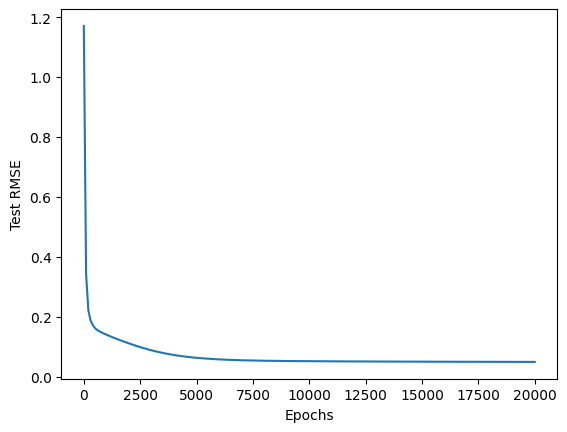

In [10]:
import matplotlib.pyplot as plt

print(epoch_log)
plt.plot([log['epoch'] for log in epoch_log], [log['rmse'] for log in epoch_log])
plt.xlabel('Epochs')
plt.ylabel('Test RMSE')

plt.show()

여러 epoch에 걸쳐 테스트한 결과 epoch이 늘어날 수록 상승폭이 줄어드는 것을 확인 할 수 있었다.

### Conlusion

이 homework에서 우리는 He initialization을 통해 각 뉴런들을 초기화 하고, feed forward를 통해 값을 예측한 다음, 오차값을 이용하여 back propagation을 이용해 gradient를 구해 이를 learning rate에 비례해 곱해줌으로서 deep neural network가 학습하는 것을 구현해 보았다. 이번 학습 환경에서 ReLU와 Sigmoid 활성 함수를 통해 두개의 함수를 비교해 보았는데, 두 수의 곱을 구하는 연속적인 문제에서는 ReLU가 Sigmoid가 더 높은 효율을 보여주고 있는것을 확인 가능했다.